# 02 · Data, problems and the pipeline (R1, R2, R9)
**Skills:** Week 4 data sourcing, missing values, outliers, edge vs cloud; Week 5 pipelines and honest charts.

In [1]:
# SETUP: make the project's own code importable, whatever folder VS Code started in.
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/admin/Desktop/smart-vitals-ipms


## 1 · Who are the patients? (R1: Low / Medium / High risk)

In [2]:
import json
from src import config
patients = pd.DataFrame(json.loads(config.PATIENTS_PATH.read_text()))
print(patients["risk_group"].value_counts().to_string())
patients[["patient_id", "age", "conditions", "risk_group", "clinician_id"]].head(8)

risk_group
Low       8
Medium    8
High      4


,patient_id,age,conditions,risk_group,clinician_id
0,P001,76,"[arrhythmia, diabetes]",High,C01
1,P002,37,[],Low,C02
2,P003,61,"[arrhythmia, hypertension]",Medium,C03
3,P004,79,"[diabetes, hypertension]",High,C04
4,P005,73,[hypertension],Medium,C01
5,P006,60,[hypertension],Low,C02
6,P007,62,[diabetes],Low,C03
7,P008,53,"[arrhythmia, diabetes]",Medium,C04


## 2 · A messy hour from the simulator (R2, R9)

In [3]:
from simulator.generator import simulate
events, observed = simulate(patients.to_dict("records"), minutes=60, seed=11, faults=True)
faults = pd.Series([e["fault"] or "clean" for e in events]).value_counts()
print(len(events), "messages arrive for", len(observed), "readings measured")
faults

1172 messages arrive for 1126 readings measured


clean            1010
stuck              60
duplicate          46
late               27
missing_vital      19
glitch             10
Name: count, dtype: int64

**YOUR TURN:** which of these problems can the *edge* fix cheaply, and which need the *cloud*? (Week 4: four constraints, four questions.)

## 3 · Each cleaning step, one at a time

In [4]:
from src import pipeline as P
obs = pd.DataFrame(observed)
step0 = P.prepare(obs)
step1 = P.range_check(step0)
step2 = P.drop_stuck_sensor(step1)
step3 = P.fill_short_gaps(step2)
summary = pd.DataFrame({
    "after step": ["raw", "range check", "stuck sensor", "short-gap fill"],
    "missing heart rates": [int(s["heart_rate"].isna().sum()) for s in (step0, step1, step2, step3)],
    "missing SpO2": [int(s["spo2"].isna().sum()) for s in (step0, step1, step2, step3)],
})
summary

,after step,missing heart rates,missing SpO2
0,raw,2,4
1,range check,6,6
2,stuck sensor,15,19
3,short-gap fill,4,6


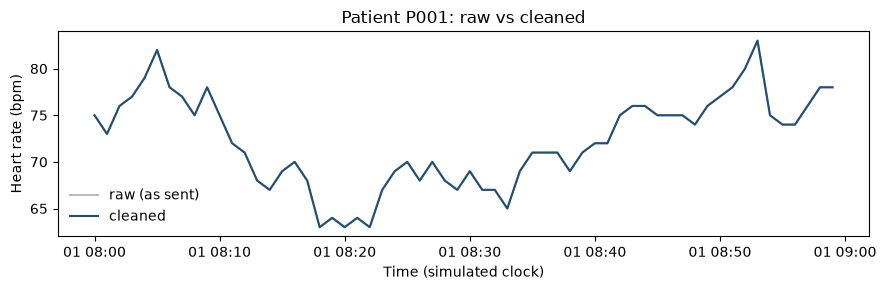

In [5]:
# One patient, raw vs cleaned heart rate (honest chart: units labelled, fixed sensible range)
bad = obs[obs["fault"] == "glitch"]["patient_id"]
pid = bad.iloc[0] if len(bad) else obs["patient_id"].iloc[0]
a = step0[step0.patient_id == pid]; b = step3[step3.patient_id == pid]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(a["timestamp"], a["heart_rate"], color="#bbbbbb", label="raw (as sent)")
ax.plot(b["timestamp"], b["heart_rate"], color="#1f4e79", label="cleaned")
ax.set_ylabel("Heart rate (bpm)"); ax.set_xlabel("Time (simulated clock)"); ax.legend(frameon=False)
ax.set_title(f"Patient {pid}: raw vs cleaned"); plt.tight_layout(); plt.show()

## 4 · The label rule (what Normal / Warning / Critical mean here)

In [6]:
from src import rules
examples = [
    {"heart_rate": 72, "spo2": 98, "systolic": 120, "temperature": 36.8},
    {"heart_rate": 72, "spo2": 90, "systolic": 120, "temperature": 36.8},
    {"heart_rate": 135, "spo2": 88, "systolic": 92, "temperature": 39.4},
]
pd.DataFrame([{**e, "points": rules.score(e), "label": rules.label(e)} for e in examples])

,heart_rate,spo2,systolic,temperature,points,label
0,72,98,120,36.8,0,Normal
1,72,90,120,36.8,3,Warning
2,135,88,92,39.4,10,Critical


**YOUR TURN:** how does this differ from NEWS2 (Royal College of Physicians, 2017)? Read it, cite it, and list the differences.

## 5 · Edge: a tiny early-warning rule that works offline

In [7]:
from simulator import edge
print(edge.early_warning({"spo2": 85, "heart_rate": 160}))
clean, blanked = edge.range_check({"heart_rate": 250, "spo2": 97})
print(clean, "blanked:", blanked)

['SpO2 85% is very low', 'heart rate 160 is very high']
{'heart_rate': None, 'spo2': 97} blanked: ['heart_rate']
